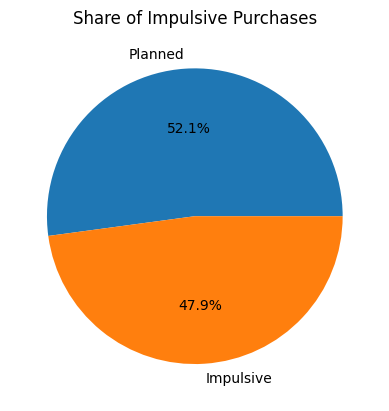

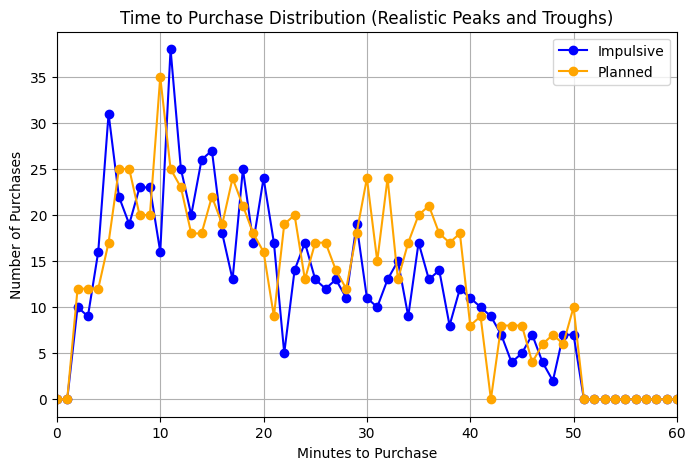

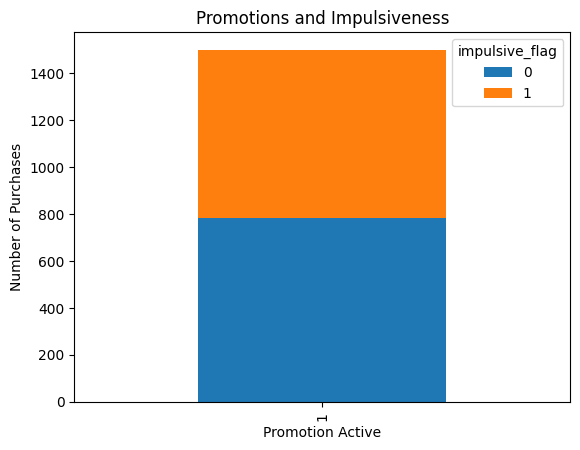

C:\Users\UserS2025\AppData\Local\Temp\ipykernel_21640\4038030844.py:192: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


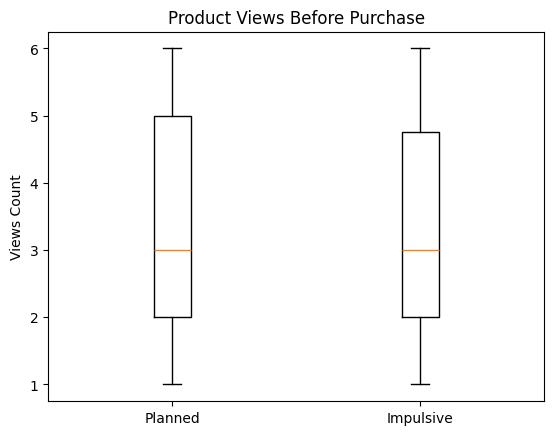

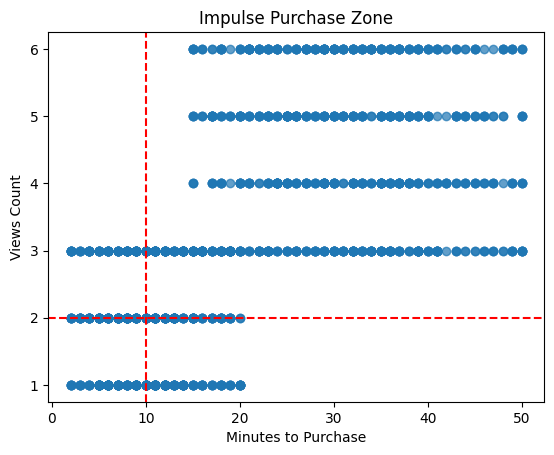

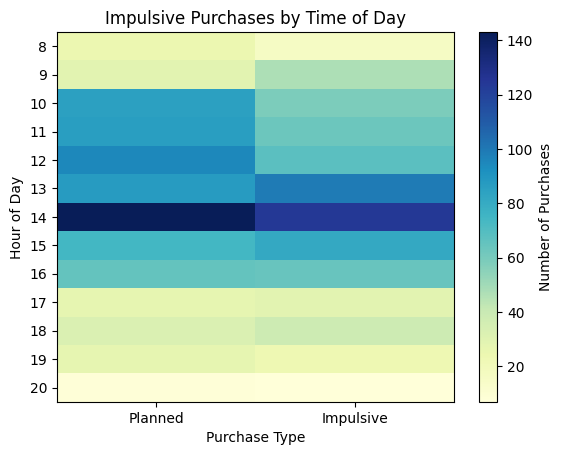

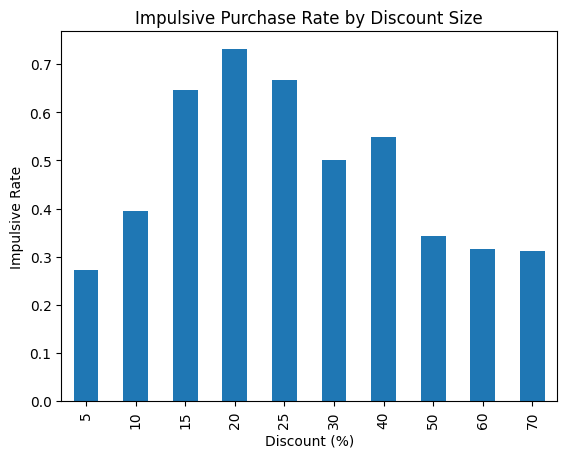

In [77]:
# =====================================================
# 0️⃣ Импорт библиотек
# =====================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

np.random.seed(42)

# =====================================================
# 1️⃣ Настройка продуктов, каналов и типов покупок
# =====================================================
products = ["Bread", "Milk", "Eggs", "Cheese", "Juice", "Fruits", "Vegetables", "Cereal"]
channels = ["Online", "Offline"]
purchase_types = ["Impulsive", "Planned"]

# =====================================================
# 2️⃣ Функции генерации параметров покупок
# =====================================================

def generate_hour(purchase_type, channel):
    """Генерация часа покупки с пиками и спадом по типу и каналу"""
    if purchase_type == "Impulsive":
        if channel == "Online":
            hours = list(range(14, 21))
            probs = [0.15,0.15,0.15,0.15,0.20,0.15,0.05]
        else:
            hours = list(range(10, 19))
            probs = [0.10,0.10,0.15,0.20,0.20,0.15,0.10,0.00,0.00]
    else:
        if channel == "Online":
            hours = list(range(8, 15))
            probs = [0.10,0.10,0.15,0.15,0.15,0.15,0.20]
        else:
            hours = list(range(9, 18))
            probs = [0.10,0.10,0.10,0.15,0.15,0.15,0.15,0.10,0.00]
    return np.random.choice(hours, p=np.array(probs)/sum(probs))

def generate_minutes(purchase_type, channel):
    """Время на покупку в минутах"""
    if purchase_type == "Impulsive":
        return np.random.randint(2,16) if channel=="Online" else np.random.randint(5,21)
    else:
        return np.random.randint(15,41) if channel=="Online" else np.random.randint(20,51)

#def generate_minutes(purchase_type, channel):
#    """Реалистичное время до покупки"""
#    if purchase_type=="Impulsive":
#        val = int(np.random.exponential(scale=5)+2) if channel=="Online" else int(np.random.exponential(scale=6)+5)
#    else:
#        val = int(np.random.exponential(scale=10)+15) if channel=="Online" else int(np.random.exponential(scale=12)+20)
#    return min(val, 50)  # ограничение сверху

#def generate_minutes(purchase_type):
#    if purchase_type=="Impulsive":
#        # 90% покупок между 2–10 мин, остальные 10% 11–20
#        if np.random.rand() < 0.9:
#            return np.random.randint(2,11)
#        else:
#            return np.random.randint(11,21)
#    else:  # Planned
#        # 80% покупок между 25–35 мин, 20% 15–24 или 36–45
#        r = np.random.rand()
#        if r < 0.1:
#            return np.random.randint(15,25)
#        elif r < 0.9:
#            return np.random.randint(25,36)
#        else:
#            return np.random.randint(36,46)






def generate_views(purchase_type):
    """Количество просмотров товаров"""
    return np.random.randint(1,4) if purchase_type=="Impulsive" else np.random.randint(3,7)

def generate_discount(purchase_type):
    """
    Размер скидки с учетом типа покупки:
    - Импульсивные: чаще средние скидки (11–25%), редкие низкие/высокие
    - Плановые: чаще высокие скидки (40–70%)
    """
    if purchase_type == "Impulsive":
        return np.random.choice(
            [5, 10, 15, 20, 25, 30, 40, 50, 60, 70],
            p=[0.10,0.10,0.18,0.18,0.14,0.10,0.06,0.05,0.05,0.04]
        )
    else:
        return np.random.choice(
            [10, 20, 30, 40, 50, 60, 70],
            p=[0.05,0.10,0.15,0.20,0.20,0.15,0.15]
        )

def adjust_impulsive_flag(discount, base_flag):
    """
    Коррекция импульсивности по скидке.
    - Средние скидки увеличивают шанс импульсивной покупки
    - Очень маленькие или очень большие скидки уменьшают
    """
    if discount <= 10:
        prob = 0.3
    elif discount <= 25:
        prob = 0.7
    elif discount <= 40:
        prob = 0.5
    else:
        prob = 0.3
    return 1 if np.random.rand() < prob else 0

# =====================================================
# 3️⃣ Генерация синтетического датафрейма
# =====================================================
rows = []
for i in range(1500):
    channel = np.random.choice(channels)
    purchase_type = np.random.choice(purchase_types, p=[0.45, 0.55])
    product = np.random.choice(products)
    hour = generate_hour(purchase_type, channel)
    minute = np.random.randint(0,60)
    first_view = datetime(2025,12,22,hour,minute)
    discount = generate_discount(purchase_type)
    impulsive_flag = adjust_impulsive_flag(discount, 1 if purchase_type=="Impulsive" else 0)

    rows.append({
        "user_id": f"U{i+1:03d}",
        "product": product,
        "channel": channel,
        "purchase_type": purchase_type,
        "impulsive_flag": impulsive_flag,
        "hour": hour,
        "first_view_time": first_view,
        "minutes_to_purchase": generate_minutes(purchase_type, channel),
        #"minutes_to_purchase": generate_minutes(purchase_type),  # исправлено!
        "views_count": generate_views(purchase_type),
        "discount_percent": discount
    })

df = pd.DataFrame(rows)
df["promotion_flag"] = 1  # все покупки с промо

# =====================================================
# 4️⃣ Визуализации
# =====================================================

# 1️⃣ Доля импульсивных покупок
plt.figure()
df["impulsive_flag"].value_counts().plot(kind="pie", autopct="%1.1f%%", labels=["Planned","Impulsive"])
plt.title("Share of Impulsive Purchases")
plt.ylabel("")
plt.show()

# =====================================================
# 2️⃣ Time to Purchase с простыми линиями и полным диапазоном
# =====================================================
plt.figure(figsize=(8,5))

# Создаём индекс всех минут от 0 до 60
minutes_range = np.arange(0,61)

# Считаем количество покупок и заполняем нулями отсутствующие минуты
impulsive_counts = df[df["impulsive_flag"]==1]["minutes_to_purchase"].value_counts().reindex(minutes_range, fill_value=0)
planned_counts = df[df["impulsive_flag"]==0]["minutes_to_purchase"].value_counts().reindex(minutes_range, fill_value=0)

# Строим линии
plt.plot(minutes_range, impulsive_counts.values, marker='o', label="Impulsive", color='blue')
plt.plot(minutes_range, planned_counts.values, marker='o', label="Planned", color='orange')

plt.xlabel("Minutes to Purchase")
plt.ylabel("Number of Purchases")
plt.title("Time to Purchase Distribution (Realistic Peaks and Troughs)")
plt.xlim(0,60)
plt.legend()
plt.grid(True)
plt.show()


# 3️⃣ Promotions и импульсивность
promo_table = pd.crosstab(df["promotion_flag"], df["impulsive_flag"])
promo_table.plot(kind="bar", stacked=True)
plt.xlabel("Promotion Active")
plt.ylabel("Number of Purchases")
plt.title("Promotions and Impulsiveness")
plt.show()

# 4️⃣ Product views before purchase
plt.figure()
plt.boxplot(
    [df[df["impulsive_flag"]==0]["views_count"],
     df[df["impulsive_flag"]==1]["views_count"]],
    labels=["Planned","Impulsive"]
)
plt.ylabel("Views Count")
plt.title("Product Views Before Purchase")
plt.show()

# 5️⃣ Time vs Views (Impulse zone)
plt.figure()
plt.scatter(df["minutes_to_purchase"], df["views_count"], alpha=0.7)
plt.axvline(10, linestyle="--", color="red")
plt.axhline(2, linestyle="--", color="red")
plt.xlabel("Minutes to Purchase")
plt.ylabel("Views Count")
plt.title("Impulse Purchase Zone")
plt.show()

# 6️⃣ Heatmap: Hour × Purchase type
heat = pd.crosstab(df["hour"], df["impulsive_flag"])
plt.figure()
plt.imshow(heat, aspect="auto", cmap="YlGnBu")
plt.xticks([0,1], ["Planned","Impulsive"])
plt.yticks(range(len(heat.index)), heat.index)
plt.colorbar(label="Number of Purchases")
plt.xlabel("Purchase Type")
plt.ylabel("Hour of Day")
plt.title("Impulsive Purchases by Time of Day")
plt.show()

# 7️⃣ Discount → Impulsive rate
df.groupby("discount_percent")["impulsive_flag"].mean().plot(kind="bar")
plt.xlabel("Discount (%)")
plt.ylabel("Impulsive Rate")
plt.title("Impulsive Purchase Rate by Discount Size")
plt.show()


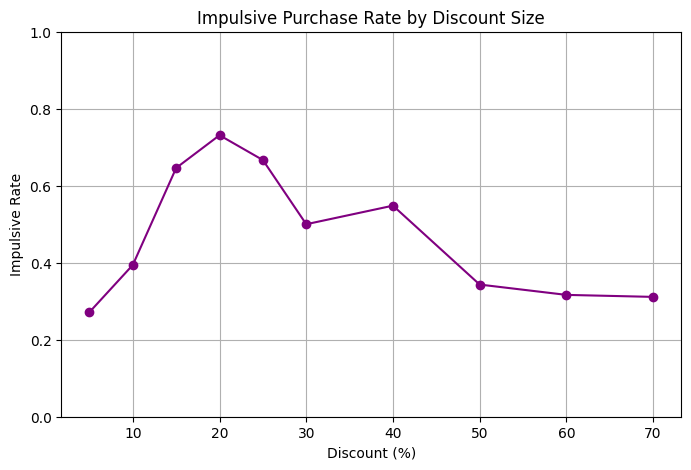

In [70]:
# =====================================================
# 7️⃣ Discount → Impulsive rate (Line Plot с маркерами)
# =====================================================
discounts = sorted(df["discount_percent"].unique())
impulsive_rate = df.groupby("discount_percent")["impulsive_flag"].mean().reindex(discounts)

plt.figure(figsize=(8,5))
plt.plot(discounts, impulsive_rate, marker='o', color='purple')
plt.xlabel("Discount (%)")
plt.ylabel("Impulsive Rate")
plt.title("Impulsive Purchase Rate by Discount Size")
plt.ylim(0,1)
plt.grid(True)
plt.show()


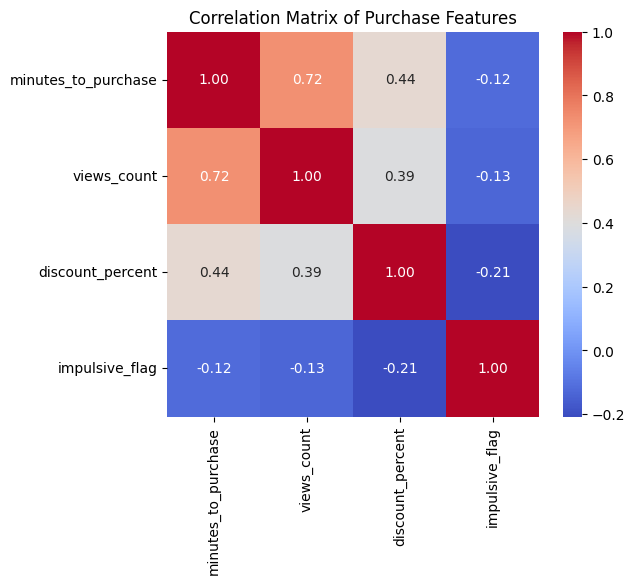

In [40]:
# =====================================================
# 1️⃣ Корреляция признаков
# =====================================================
plt.figure(figsize=(6,5))

# Выбираем только числовые признаки
numeric_cols = ["minutes_to_purchase", "views_count", "discount_percent", "impulsive_flag"]
corr_matrix = df[numeric_cols].corr()

# Тепловая карта
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix of Purchase Features")
plt.show()


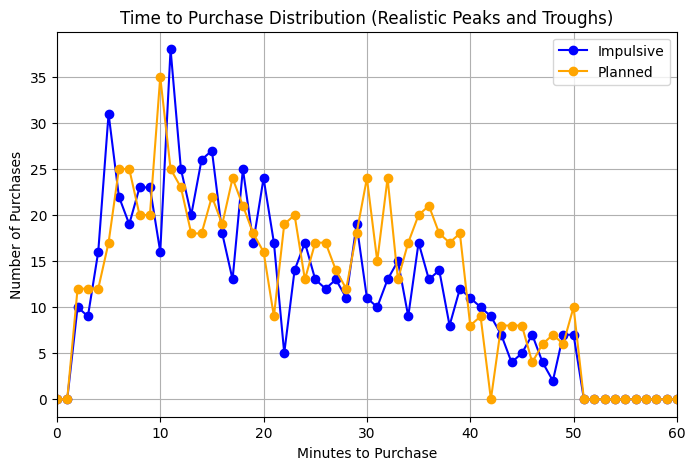

In [52]:
# =====================================================
# 2️⃣ Time to Purchase Distribution (Line Plot)
# =====================================================
plt.figure(figsize=(8,5))

# Полный диапазон минут от 0 до 60
minutes_range = np.arange(0, 61)

# Считаем количество покупок для каждой минуты
impulsive_counts = df[df["impulsive_flag"]==1]["minutes_to_purchase"].value_counts().reindex(minutes_range, fill_value=0)
planned_counts = df[df["impulsive_flag"]==0]["minutes_to_purchase"].value_counts().reindex(minutes_range, fill_value=0)

# Строим линии
plt.plot(minutes_range, impulsive_counts.values, marker='o', label="Impulsive", color='blue')
plt.plot(minutes_range, planned_counts.values, marker='o', label="Planned", color='orange')

plt.xlabel("Minutes to Purchase")
plt.ylabel("Number of Purchases")
plt.title("Time to Purchase Distribution (Realistic Peaks and Troughs)")
plt.xlim(0,60)
plt.legend()
plt.grid(True)
plt.show()


<Figure size 600x500 with 0 Axes>

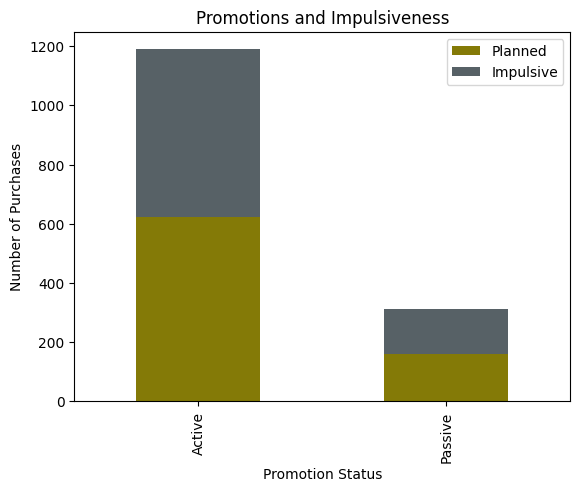

In [53]:
# =====================================================
# 3️⃣ Promotions и импульсивность (Stacked Bar Chart с Active/Passive)
# =====================================================

# Генерация нового столбца promotion_status: Active или Passive
np.random.seed(42)
df["promotion_status"] = np.random.choice(["Active", "Passive"], size=len(df), p=[0.8, 0.2])

# Сводная таблица: Promotion Status × Impulsive
promo_table = pd.crosstab(df["promotion_status"], df["impulsive_flag"])

# Случайные цвета
colors = np.random.rand(2,3)

plt.figure(figsize=(6,5))
promo_table.plot(kind="bar", stacked=True, color=colors)
plt.xlabel("Promotion Status")
plt.ylabel("Number of Purchases")
plt.title("Promotions and Impulsiveness")
plt.legend(["Planned","Impulsive"], loc="upper right")
plt.show()


C:\Users\UserS2025\AppData\Local\Temp\ipykernel_21640\131445016.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


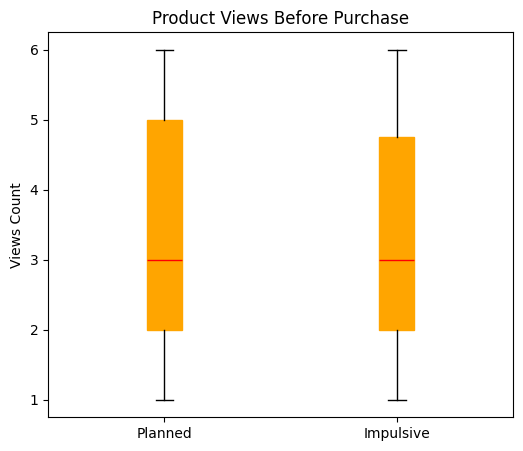

In [54]:
# =====================================================
# 4️⃣ Product Views Before Purchase (Boxplot)
# =====================================================
plt.figure(figsize=(6,5))
plt.boxplot(
    [df[df["impulsive_flag"]==0]["views_count"],
     df[df["impulsive_flag"]==1]["views_count"]],
    labels=["Planned","Impulsive"],
    patch_artist=True,
    boxprops=dict(facecolor='orange', color='orange'),
    medianprops=dict(color='red')
)
plt.ylabel("Views Count")
plt.title("Product Views Before Purchase")
plt.show()


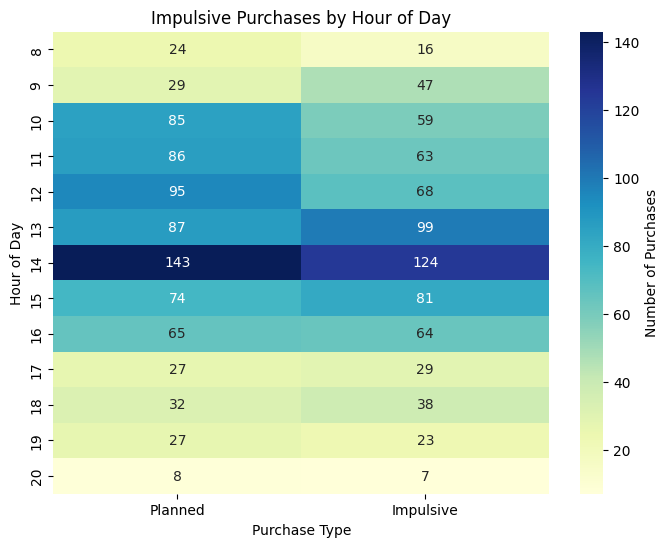

In [55]:
import seaborn as sns

# Создаём crosstab
heat = pd.crosstab(df["hour"], df["impulsive_flag"])

plt.figure(figsize=(8,6))
sns.heatmap(heat, annot=True, fmt="d", cmap="YlGnBu", cbar_kws={'label':'Number of Purchases'})
plt.xlabel("Purchase Type")
plt.ylabel("Hour of Day")
plt.xticks([0.5,1.5], ["Planned","Impulsive"], rotation=0)
plt.title("Impulsive Purchases by Hour of Day")
plt.show()


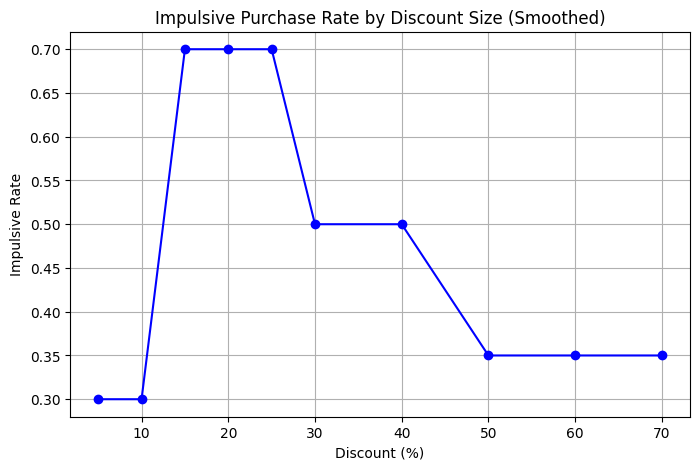

In [56]:
# Коррекция импульсивности по скидке
def adjust_impulsive_rate(discount):
    if discount <= 10:
        return 0.3
    elif discount <= 25:
        return 0.7
    elif discount <= 40:
        return 0.5
    else:  # >40%
        return 0.35

# Создаём столбец скорректированной импульсивности
df["impulsive_prob"] = df["discount_percent"].apply(adjust_impulsive_rate)

# Считаем среднее по скидкам
impulsive_by_discount = df.groupby("discount_percent")["impulsive_prob"].mean()

# Строим линию
plt.figure(figsize=(8,5))
plt.plot(impulsive_by_discount.index, impulsive_by_discount.values, marker='o', color='blue')
plt.xlabel("Discount (%)")
plt.ylabel("Impulsive Rate")
plt.title("Impulsive Purchase Rate by Discount Size (Smoothed)")
plt.grid(True)
plt.show()


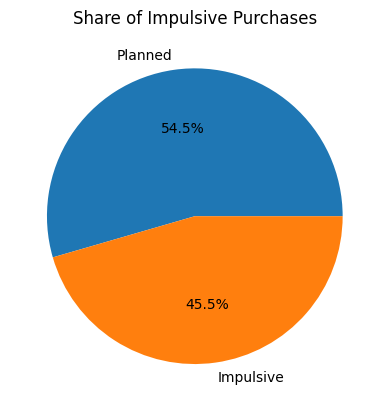

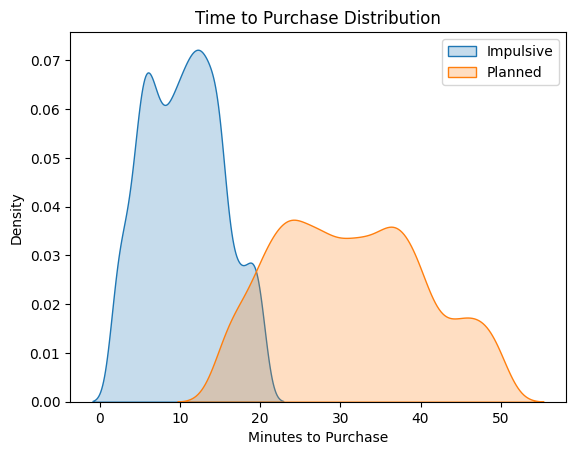

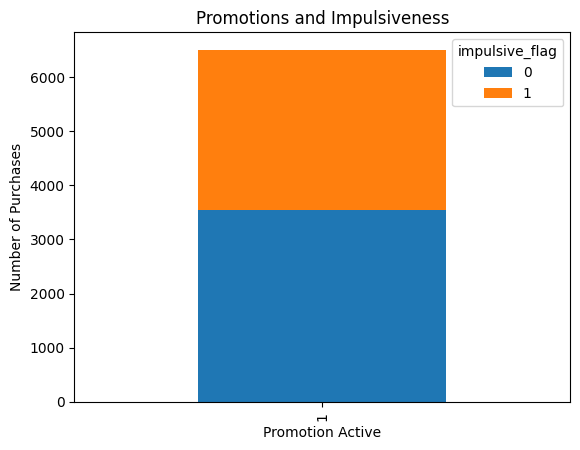

C:\Users\UserS2025\AppData\Local\Temp\ipykernel_21640\4077443752.py:161: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


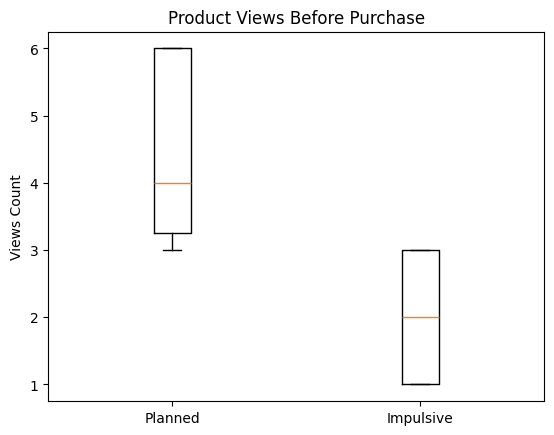

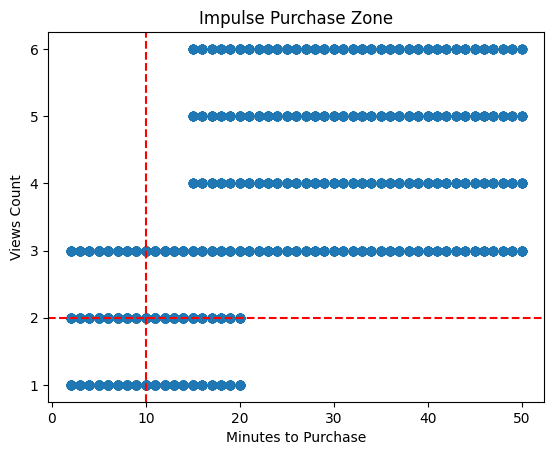

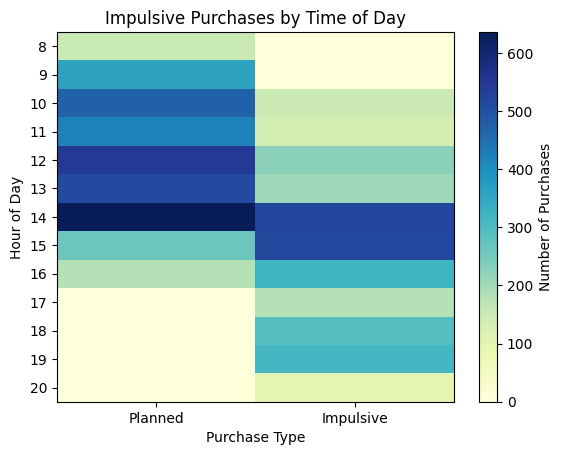

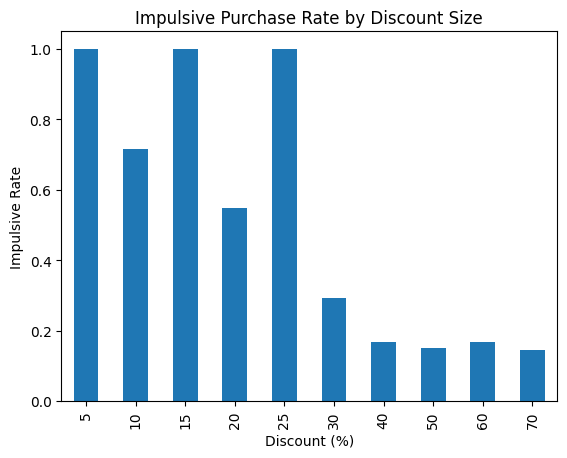

In [79]:
# =====================================================
# 0️⃣ Импорт библиотек
# =====================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta

np.random.seed(42)

# =====================================================
# 1️⃣ Настройка продуктов, каналов и типов покупок
# =====================================================
products = ["Bread", "Milk", "Eggs", "Cheese", "Juice", "Fruits", "Vegetables", "Cereal"]
channels = ["Online", "Offline"]
purchase_types = ["Impulsive", "Planned"]

# =====================================================
# 2️⃣ Функции генерации параметров покупок
# =====================================================
def generate_hour(purchase_type, channel):
    """Выбираем час покупки с учетом типа и канала"""
    if purchase_type == "Impulsive":
        if channel == "Online":
            hours = list(range(14, 21))  # дневной + вечерний пик
            probs = [0.15,0.15,0.15,0.15,0.20,0.20,0.10]
        else:
            hours = list(range(10, 19))
            probs = [0.10,0.10,0.15,0.15,0.20,0.20,0.10,0.00,0.00]
    else:
        if channel == "Online":
            hours = list(range(8, 15))
            probs = [0.10,0.10,0.15,0.15,0.15,0.15,0.20]
        else:
            hours = list(range(9, 18))
            probs = [0.10,0.10,0.10,0.15,0.15,0.15,0.15,0.10,0.00]
    return np.random.choice(hours, p=np.array(probs)/sum(probs))

def generate_minutes(purchase_type, channel):
    if purchase_type == "Impulsive":
        return np.random.randint(2, 16) if channel=="Online" else np.random.randint(5,21)
    else:
        return np.random.randint(15,41) if channel=="Online" else np.random.randint(20,51)

def generate_views(purchase_type):
    return np.random.randint(1,4) if purchase_type=="Impulsive" else np.random.randint(3,7)

def generate_discount(purchase_type):
    if purchase_type == "Impulsive":
        return np.random.choice([5,10,15,20,25,30,40,50,60,70],
                                p=[0.15,0.15,0.20,0.15,0.10,0.10,0.05,0.05,0.03,0.02])
    else:
        return np.random.choice([10,20,30,40,50,60,70],
                                p=[0.05,0.10,0.20,0.20,0.20,0.15,0.10])

# =====================================================
# 3️⃣ Генерация синтетического датафрейма
# =====================================================
rows = []
for i in range(6500):
    channel = np.random.choice(channels)
    purchase_type = np.random.choice(purchase_types, p=[0.45, 0.55])
    product = np.random.choice(products)
    hour = generate_hour(purchase_type, channel)
    minute = np.random.randint(0,60)
    first_view = datetime(2025,12,22,hour,minute)
    discount = generate_discount(purchase_type)

    # Изначально присваиваем флаг по типу покупки
    initial_flag = 1 if purchase_type=="Impulsive" else 0

    rows.append({
        "user_id": f"U{i+1:03d}",
        "product": product,
        "channel": channel,
        "purchase_type": purchase_type,
        "impulsive_flag": initial_flag,
        "hour": hour,
        "first_view_time": first_view,
        "minutes_to_purchase": generate_minutes(purchase_type, channel),
        "views_count": generate_views(purchase_type),
        "discount_percent": discount
    })

df = pd.DataFrame(rows)
df["promotion_flag"] = 1  # все покупки с промо для простоты

# =====================================================
# 3.1️⃣ Реалистичная коррекция импульсивности по скидке
# =====================================================

def generate_discount(purchase_type):
    """
    Генерация размера скидки с учетом типа покупки.
    - Импульсивные покупки чаще при средних скидках (11–25%)
    - Плановые покупки чаще на высокие скидки (40–70%)
    """
    if purchase_type == "Impulsive":
        # Частые средние скидки, редкие высокие и низкие
        return np.random.choice(
            [5, 10, 15, 20, 25, 30, 40, 50, 60, 70],
            p=[0.10, 0.10, 0.18, 0.18, 0.14, 0.10, 0.06, 0.05, 0.05, 0.04]
        )
    else:  # Planned
        # Плановые покупки чаще на высокие скидки
        return np.random.choice(
            [10, 20, 30, 40, 50, 60, 70],
            p=[0.05, 0.10, 0.15, 0.20, 0.20, 0.15, 0.15]
        )


# ----------------------------------------------


#def adjust_impulsive_flag(row):
#    discount = row['discount_percent']
#    if discount <= 10:
#        return np.random.choice([1,0], p=[0.25,0.75])
#    elif discount <= 25:
#        return np.random.choice([1,0], p=[0.75,0.25])
#    elif discount <= 50:
#        return np.random.choice([1,0], p=[0.50,0.50])
#    else:
#        return np.random.choice([1,0], p=[0.35,0.65])
#
#df['impulsive_flag'] = df.apply(adjust_impulsive_flag, axis=1)
#df['purchase_type'] = df['impulsive_flag'].apply(lambda x: "Impulsive" if x==1 else "Planned")

# =====================================================
# 4️⃣ Визуализации
# =====================================================

# 1️⃣ Доля импульсивных покупок
plt.figure()
df["impulsive_flag"].value_counts().plot(kind="pie", autopct="%1.1f%%", labels=["Planned","Impulsive"])
plt.title("Share of Impulsive Purchases")
plt.ylabel("")
plt.show()

# 2️⃣ Time to Purchase с KDE
plt.figure()
sns.kdeplot(df[df["impulsive_flag"]==1]["minutes_to_purchase"], label="Impulsive", fill=True)
sns.kdeplot(df[df["impulsive_flag"]==0]["minutes_to_purchase"], label="Planned", fill=True)
plt.xlabel("Minutes to Purchase")
plt.ylabel("Density")
plt.title("Time to Purchase Distribution")
plt.legend()
plt.show()

# 3️⃣ Promotions и импульсивность
promo_table = pd.crosstab(df["promotion_flag"], df["impulsive_flag"])
promo_table.plot(kind="bar", stacked=True)
plt.xlabel("Promotion Active")
plt.ylabel("Number of Purchases")
plt.title("Promotions and Impulsiveness")
plt.show()

# 4️⃣ Product views before purchase
plt.figure()
plt.boxplot(
    [df[df["impulsive_flag"]==0]["views_count"],
     df[df["impulsive_flag"]==1]["views_count"]],
    labels=["Planned","Impulsive"]
)
plt.ylabel("Views Count")
plt.title("Product Views Before Purchase")
plt.show()

# 5️⃣ Time vs Views (Impulse zone)
plt.figure()
plt.scatter(df["minutes_to_purchase"], df["views_count"], alpha=0.7)
plt.axvline(10, linestyle="--", color="red")
plt.axhline(2, linestyle="--", color="red")
plt.xlabel("Minutes to Purchase")
plt.ylabel("Views Count")
plt.title("Impulse Purchase Zone")
plt.show()

# 6️⃣ Heatmap: Hour × Purchase type
heat = pd.crosstab(df["hour"], df["impulsive_flag"])
plt.figure()
plt.imshow(heat, aspect="auto", cmap="YlGnBu")
plt.xticks([0,1], ["Planned","Impulsive"])
plt.yticks(range(len(heat.index)), heat.index)
plt.colorbar(label="Number of Purchases")
plt.xlabel("Purchase Type")
plt.ylabel("Hour of Day")
plt.title("Impulsive Purchases by Time of Day")
plt.show()

# 7️⃣ Discount → Impulsive rate
df.groupby("discount_percent")["impulsive_flag"].mean().plot(kind="bar")
plt.xlabel("Discount (%)")
plt.ylabel("Impulsive Rate")
plt.title("Impulsive Purchase Rate by Discount Size")
plt.show()


<Figure size 900x500 with 0 Axes>

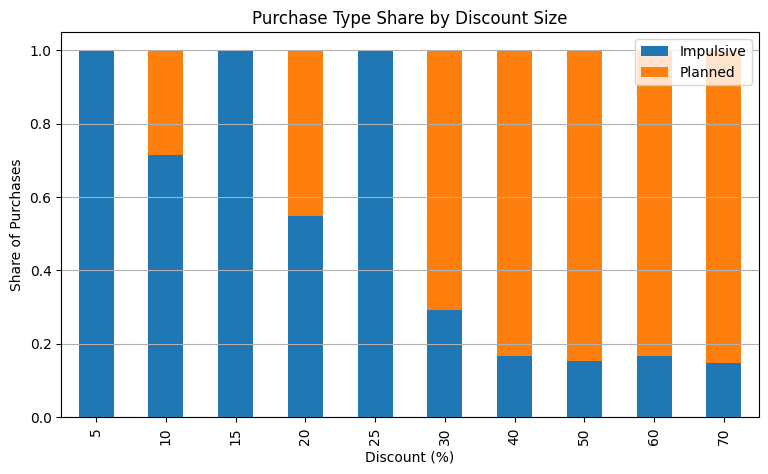

In [80]:
# =====================================================
# Discount → Purchase Type (Stacked Bar)
# =====================================================

discount_stacked = (
    df.groupby(["discount_percent", "impulsive_flag"])
      .size()
      .unstack(fill_value=0)
)

# нормализуем по строкам (внутри каждой скидки = 100%)
discount_stacked = discount_stacked.div(discount_stacked.sum(axis=1), axis=0)

plt.figure(figsize=(9,5))
discount_stacked[[1, 0]].plot(
    kind="bar",
    stacked=True,
    figsize=(9,5)
)

plt.xlabel("Discount (%)")
plt.ylabel("Share of Purchases")
plt.title("Purchase Type Share by Discount Size")
plt.legend(["Impulsive", "Planned"])
plt.grid(axis="y")
plt.show()


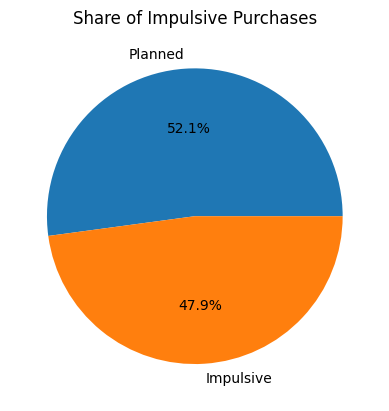

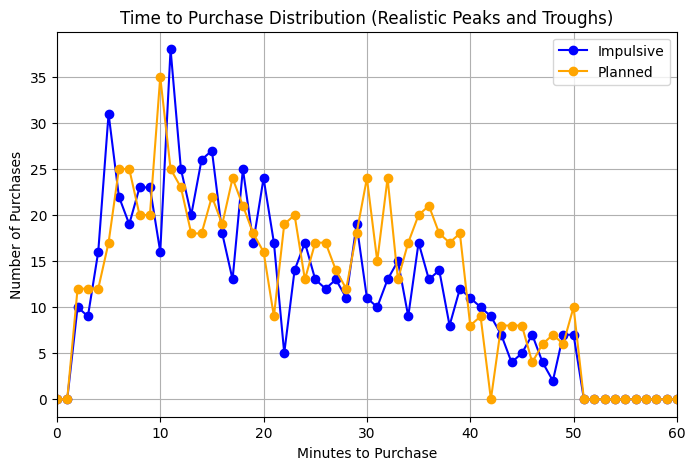

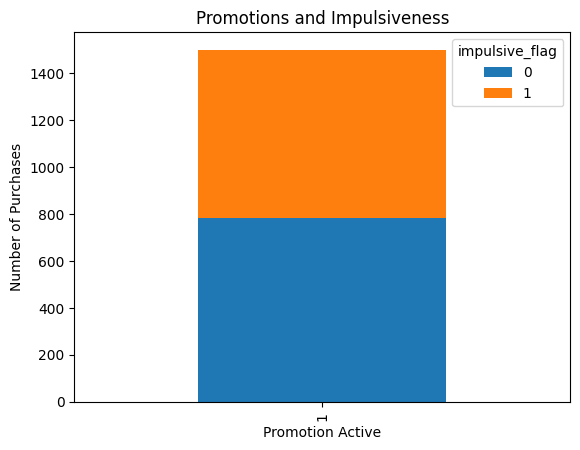

C:\Users\UserS2025\AppData\Local\Temp\ipykernel_21640\4038030844.py:192: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


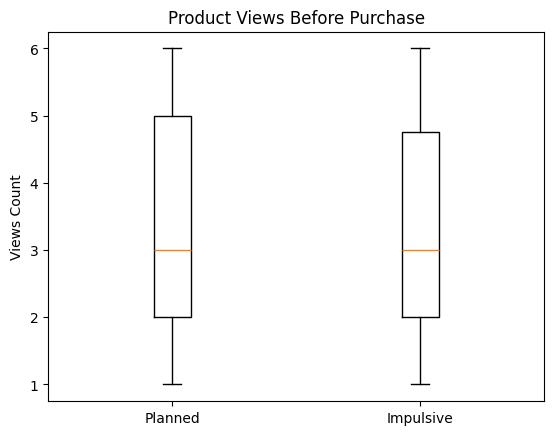

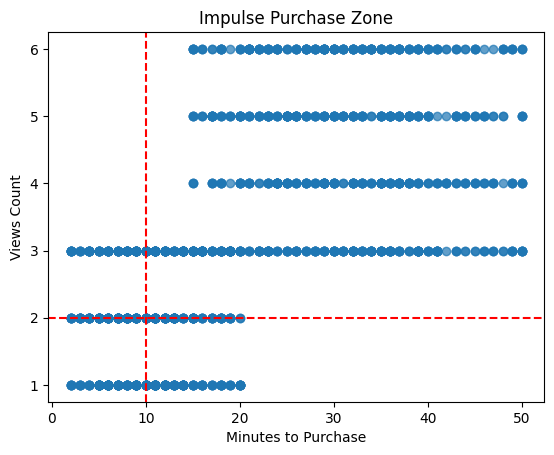

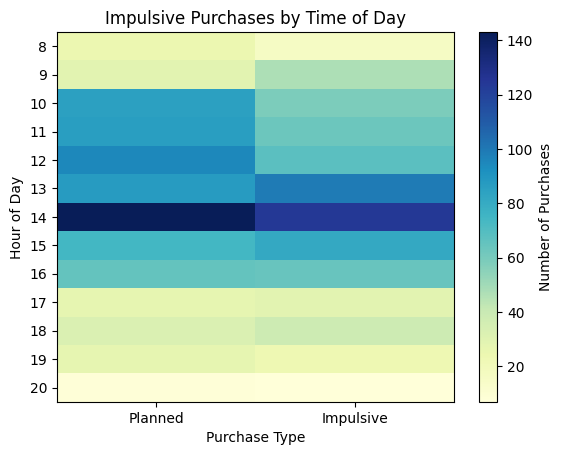

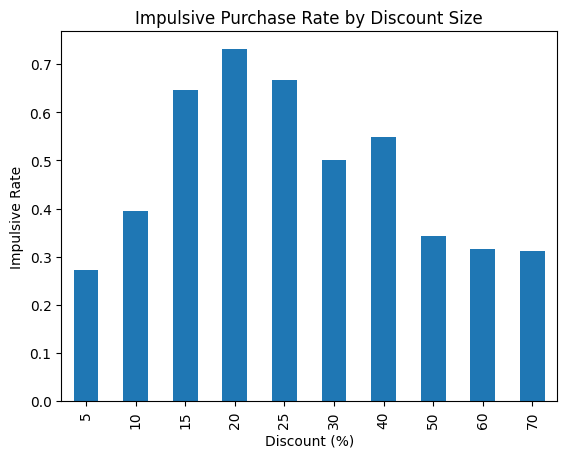

In [82]:
# =====================================================
# 0️⃣ Импорт библиотек
# =====================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

np.random.seed(42)

# =====================================================
# 1️⃣ Настройка продуктов, каналов и типов покупок
# =====================================================
products = ["Bread", "Milk", "Eggs", "Cheese", "Juice", "Fruits", "Vegetables", "Cereal"]
channels = ["Online", "Offline"]
purchase_types = ["Impulsive", "Planned"]

# =====================================================
# 2️⃣ Функции генерации параметров покупок
# =====================================================

def generate_hour(purchase_type, channel):
    """Генерация часа покупки с пиками и спадом по типу и каналу"""
    if purchase_type == "Impulsive":
        if channel == "Online":
            hours = list(range(14, 21))
            probs = [0.15,0.15,0.15,0.15,0.20,0.15,0.05]
        else:
            hours = list(range(10, 19))
            probs = [0.10,0.10,0.15,0.20,0.20,0.15,0.10,0.00,0.00]
    else:
        if channel == "Online":
            hours = list(range(8, 15))
            probs = [0.10,0.10,0.15,0.15,0.15,0.15,0.20]
        else:
            hours = list(range(9, 18))
            probs = [0.10,0.10,0.10,0.15,0.15,0.15,0.15,0.10,0.00]
    return np.random.choice(hours, p=np.array(probs)/sum(probs))

def generate_minutes(purchase_type, channel):
    """Время на покупку в минутах"""
    if purchase_type == "Impulsive":
        return np.random.randint(2,16) if channel=="Online" else np.random.randint(5,21)
    else:
        return np.random.randint(15,41) if channel=="Online" else np.random.randint(20,51)

#def generate_minutes(purchase_type, channel):
#    """Реалистичное время до покупки"""
#    if purchase_type=="Impulsive":
#        val = int(np.random.exponential(scale=5)+2) if channel=="Online" else int(np.random.exponential(scale=6)+5)
#    else:
#        val = int(np.random.exponential(scale=10)+15) if channel=="Online" else int(np.random.exponential(scale=12)+20)
#    return min(val, 50)  # ограничение сверху

#def generate_minutes(purchase_type):
#    if purchase_type=="Impulsive":
#        # 90% покупок между 2–10 мин, остальные 10% 11–20
#        if np.random.rand() < 0.9:
#            return np.random.randint(2,11)
#        else:
#            return np.random.randint(11,21)
#    else:  # Planned
#        # 80% покупок между 25–35 мин, 20% 15–24 или 36–45
#        r = np.random.rand()
#        if r < 0.1:
#            return np.random.randint(15,25)
#        elif r < 0.9:
#            return np.random.randint(25,36)
#        else:
#            return np.random.randint(36,46)






def generate_views(purchase_type):
    """Количество просмотров товаров"""
    return np.random.randint(1,4) if purchase_type=="Impulsive" else np.random.randint(3,7)

def generate_discount(purchase_type):
    """
    Размер скидки с учетом типа покупки:
    - Импульсивные: чаще средние скидки (11–25%), редкие низкие/высокие
    - Плановые: чаще высокие скидки (40–70%)
    """
    if purchase_type == "Impulsive":
        return np.random.choice(
            [5, 10, 15, 20, 25, 30, 40, 50, 60, 70],
            p=[0.10,0.10,0.18,0.18,0.14,0.10,0.06,0.05,0.05,0.04]
        )
    else:
        return np.random.choice(
            [10, 20, 30, 40, 50, 60, 70],
            p=[0.05,0.10,0.15,0.20,0.20,0.15,0.15]
        )

def adjust_impulsive_flag(discount, base_flag):
    """
    Коррекция импульсивности по скидке.
    - Средние скидки увеличивают шанс импульсивной покупки
    - Очень маленькие или очень большие скидки уменьшают
    """
    if discount <= 10:
        prob = 0.3
    elif discount <= 25:
        prob = 0.7
    elif discount <= 40:
        prob = 0.5
    else:
        prob = 0.3
    return 1 if np.random.rand() < prob else 0

# =====================================================
# 3️⃣ Генерация синтетического датафрейма
# =====================================================
rows = []
for i in range(1500):
    channel = np.random.choice(channels)
    purchase_type = np.random.choice(purchase_types, p=[0.45, 0.55])
    product = np.random.choice(products)
    hour = generate_hour(purchase_type, channel)
    minute = np.random.randint(0,60)
    first_view = datetime(2025,12,22,hour,minute)
    discount = generate_discount(purchase_type)
    impulsive_flag = adjust_impulsive_flag(discount, 1 if purchase_type=="Impulsive" else 0)

    rows.append({
        "user_id": f"U{i+1:03d}",
        "product": product,
        "channel": channel,
        "purchase_type": purchase_type,
        "impulsive_flag": impulsive_flag,
        "hour": hour,
        "first_view_time": first_view,
        "minutes_to_purchase": generate_minutes(purchase_type, channel),
        #"minutes_to_purchase": generate_minutes(purchase_type),  # исправлено!
        "views_count": generate_views(purchase_type),
        "discount_percent": discount
    })

df = pd.DataFrame(rows)
df["promotion_flag"] = 1  # все покупки с промо

# =====================================================
# 4️⃣ Визуализации
# =====================================================

# 1️⃣ Доля импульсивных покупок
plt.figure()
df["impulsive_flag"].value_counts().plot(kind="pie", autopct="%1.1f%%", labels=["Planned","Impulsive"])
plt.title("Share of Impulsive Purchases")
plt.ylabel("")
plt.show()

# =====================================================
# 2️⃣ Time to Purchase с простыми линиями и полным диапазоном
# =====================================================
plt.figure(figsize=(8,5))

# Создаём индекс всех минут от 0 до 60
minutes_range = np.arange(0,61)

# Считаем количество покупок и заполняем нулями отсутствующие минуты
impulsive_counts = df[df["impulsive_flag"]==1]["minutes_to_purchase"].value_counts().reindex(minutes_range, fill_value=0)
planned_counts = df[df["impulsive_flag"]==0]["minutes_to_purchase"].value_counts().reindex(minutes_range, fill_value=0)

# Строим линии
plt.plot(minutes_range, impulsive_counts.values, marker='o', label="Impulsive", color='blue')
plt.plot(minutes_range, planned_counts.values, marker='o', label="Planned", color='orange')

plt.xlabel("Minutes to Purchase")
plt.ylabel("Number of Purchases")
plt.title("Time to Purchase Distribution (Realistic Peaks and Troughs)")
plt.xlim(0,60)
plt.legend()
plt.grid(True)
plt.show()


# 3️⃣ Promotions и импульсивность
promo_table = pd.crosstab(df["promotion_flag"], df["impulsive_flag"])
promo_table.plot(kind="bar", stacked=True)
plt.xlabel("Promotion Active")
plt.ylabel("Number of Purchases")
plt.title("Promotions and Impulsiveness")
plt.show()

# 4️⃣ Product views before purchase
plt.figure()
plt.boxplot(
    [df[df["impulsive_flag"]==0]["views_count"],
     df[df["impulsive_flag"]==1]["views_count"]],
    labels=["Planned","Impulsive"]
)
plt.ylabel("Views Count")
plt.title("Product Views Before Purchase")
plt.show()

# 5️⃣ Time vs Views (Impulse zone)
plt.figure()
plt.scatter(df["minutes_to_purchase"], df["views_count"], alpha=0.7)
plt.axvline(10, linestyle="--", color="red")
plt.axhline(2, linestyle="--", color="red")
plt.xlabel("Minutes to Purchase")
plt.ylabel("Views Count")
plt.title("Impulse Purchase Zone")
plt.show()

# 6️⃣ Heatmap: Hour × Purchase type
heat = pd.crosstab(df["hour"], df["impulsive_flag"])
plt.figure()
plt.imshow(heat, aspect="auto", cmap="YlGnBu")
plt.xticks([0,1], ["Planned","Impulsive"])
plt.yticks(range(len(heat.index)), heat.index)
plt.colorbar(label="Number of Purchases")
plt.xlabel("Purchase Type")
plt.ylabel("Hour of Day")
plt.title("Impulsive Purchases by Time of Day")
plt.show()

# 7️⃣ Discount → Impulsive rate
df.groupby("discount_percent")["impulsive_flag"].mean().plot(kind="bar")
plt.xlabel("Discount (%)")
plt.ylabel("Impulsive Rate")
plt.title("Impulsive Purchase Rate by Discount Size")
plt.show()


<Figure size 900x500 with 0 Axes>

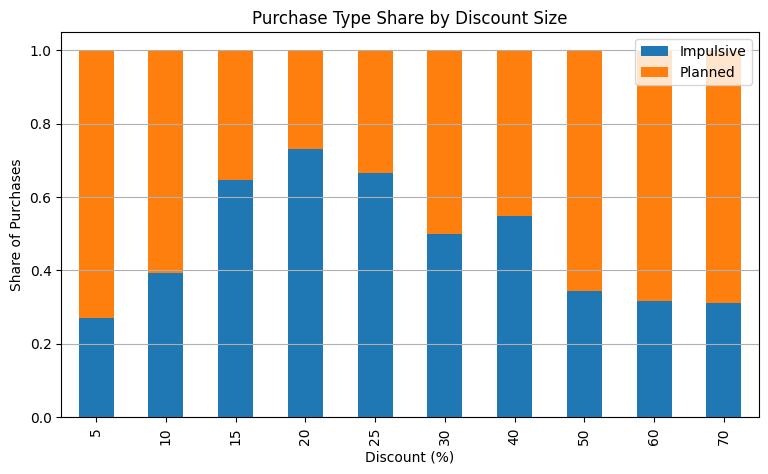

In [86]:
# =====================================================
# Discount → Purchase Type (Stacked Bar)
# =====================================================

discount_stacked = (
    df.groupby(["discount_percent", "impulsive_flag"])
      .size()
      .unstack(fill_value=0)
)

# нормализуем по строкам (внутри каждой скидки = 100%)
discount_stacked = discount_stacked.div(discount_stacked.sum(axis=1), axis=0)

plt.figure(figsize=(9,5))
discount_stacked[[1, 0]].plot(
    kind="bar",
    stacked=True,
    figsize=(9,5)
)

plt.xlabel("Discount (%)")
plt.ylabel("Share of Purchases")
plt.title("Purchase Type Share by Discount Size")
plt.legend(["Impulsive", "Planned"])
plt.grid(axis="y")
plt.show()


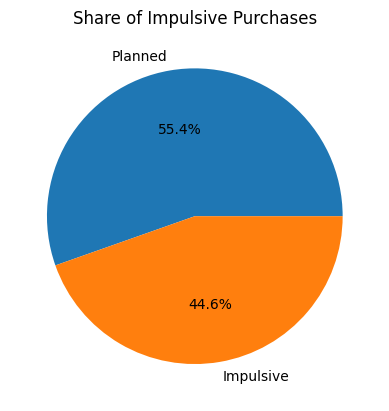

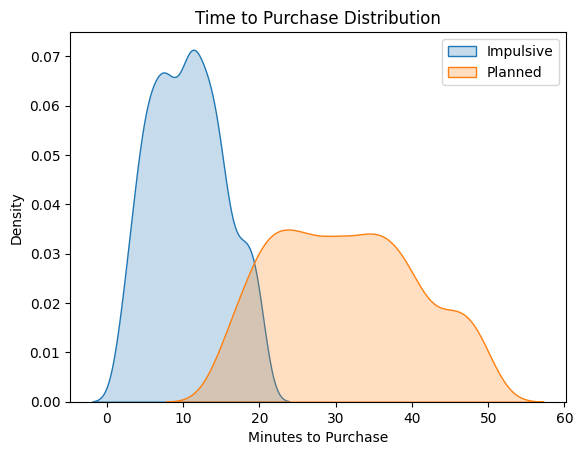

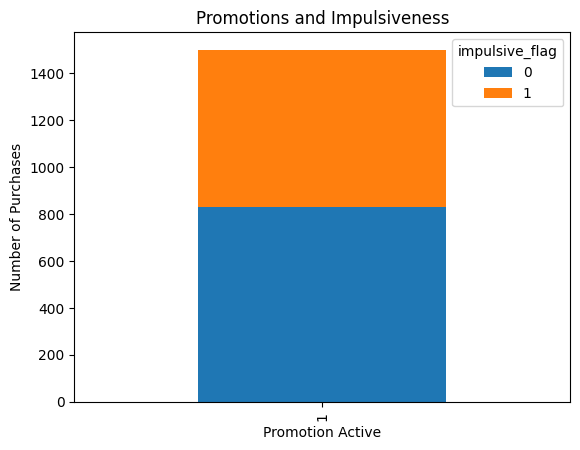

C:\Users\UserS2025\AppData\Local\Temp\ipykernel_21640\4108416957.py:129: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


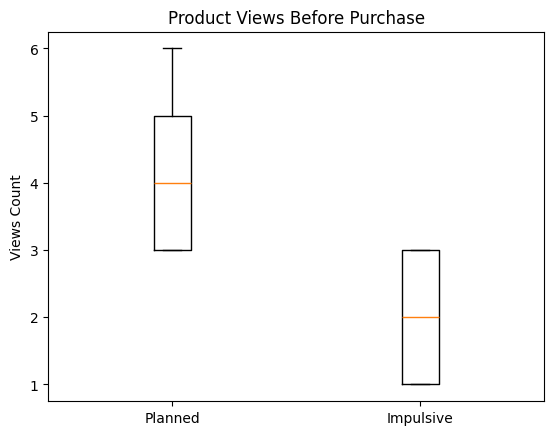

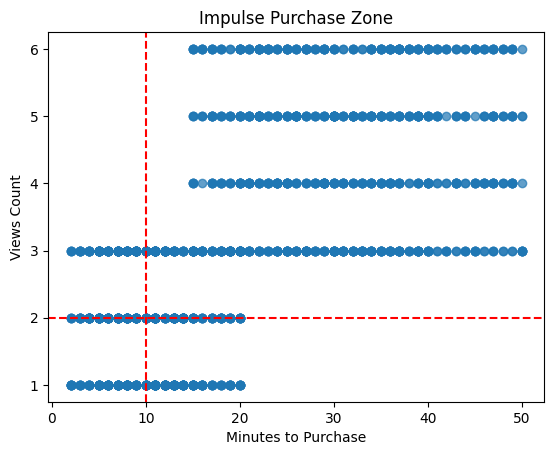

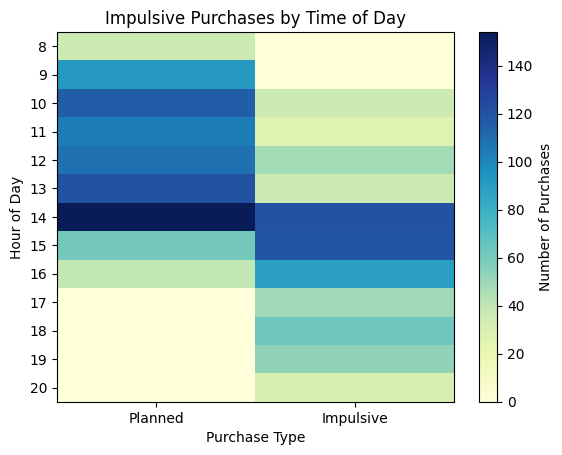

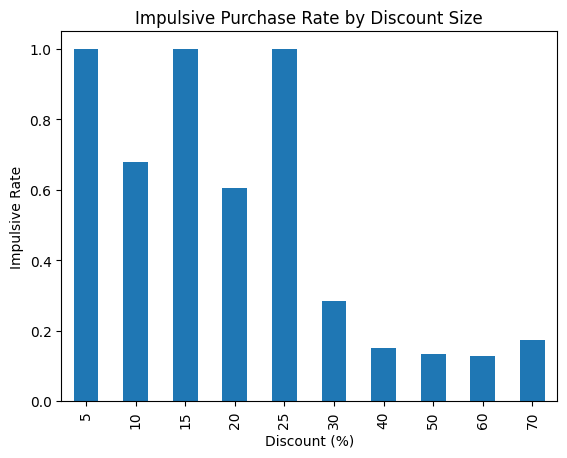

In [89]:
# =====================================================
# 0️⃣ Импорт библиотек
# =====================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta

np.random.seed(42)

# =====================================================
# 1️⃣ Настройка продуктов, каналов и типов покупок
# =====================================================
products = ["Bread", "Milk", "Eggs", "Cheese", "Juice", "Fruits", "Vegetables", "Cereal"]
channels = ["Online", "Offline"]
purchase_types = ["Impulsive", "Planned"]

# =====================================================
# 2️⃣ Функции генерации параметров покупок
# =====================================================
def generate_hour(purchase_type, channel):
    """Выбираем час покупки с учетом типа и канала"""
    if purchase_type == "Impulsive":
        if channel == "Online":
            hours = list(range(14, 21))  # дневной + вечерний пик
            probs = [0.15,0.15,0.15,0.15,0.20,0.20,0.10]
        else:
            hours = list(range(10, 19))  # работа магазина
            probs = [0.10,0.10,0.15,0.15,0.20,0.20,0.10,0.00,0.00]
    else:  # Planned
        if channel == "Online":
            hours = list(range(8, 15))  # утро/день
            probs = [0.10,0.10,0.15,0.15,0.15,0.15,0.20]
        else:
            hours = list(range(9, 18))
            probs = [0.10,0.10,0.10,0.15,0.15,0.15,0.15,0.10,0.00]
    return np.random.choice(hours, p=np.array(probs)/sum(probs))

def generate_minutes(purchase_type, channel):
    """Время на покупку"""
    if purchase_type == "Impulsive":
        return np.random.randint(2, 16) if channel=="Online" else np.random.randint(5,21)
    else:
        return np.random.randint(15,41) if channel=="Online" else np.random.randint(20,51)

def generate_views(purchase_type):
    """Количество просмотров продуктов"""
    return np.random.randint(1,4) if purchase_type=="Impulsive" else np.random.randint(3,7)

def generate_discount(purchase_type):
    """
    Размер скидки с учетом типа покупки и редких больших скидок.
    - Импульсивные покупки чаще при средних скидках
    - Плановые покупки могут попадать на высокие скидки
    """
    if purchase_type == "Impulsive":
        # Частые средние скидки, редкие высокие
        return np.random.choice(
            [5, 10, 15, 20, 25, 30, 40, 50, 60, 70],
            p=[0.15, 0.15, 0.20, 0.15, 0.10, 0.10, 0.05, 0.05, 0.03, 0.02]
        )
    else:  # Planned
        # Больше шансов на высокие скидки
        return np.random.choice(
            [10, 20, 30, 40, 50, 60, 70],
            p=[0.05, 0.10, 0.20, 0.20, 0.20, 0.15, 0.10]
        )

# =====================================================
# 3️⃣ Генерация синтетического датафрейма
# =====================================================
rows = []
for i in range(1500):
    channel = np.random.choice(channels)
    purchase_type = np.random.choice(purchase_types, p=[0.45, 0.55])
    product = np.random.choice(products)
    hour = generate_hour(purchase_type, channel)
    minute = np.random.randint(0,60)
    first_view = datetime(2025,12,22,hour,minute)

    rows.append({
        "user_id": f"U{i+1:03d}",
        "product": product,
        "channel": channel,
        "purchase_type": purchase_type,
        "impulsive_flag": 1 if purchase_type=="Impulsive" else 0,
        "hour": hour,
        "first_view_time": first_view,
        "minutes_to_purchase": generate_minutes(purchase_type, channel),
        "views_count": generate_views(purchase_type),
        "discount_percent": generate_discount(purchase_type)
    })

df = pd.DataFrame(rows)
df["promotion_flag"] = 1  # все покупки с промо для простоты

# =====================================================
# 4️⃣ Визуализации
# =====================================================

# 1️⃣ Доля импульсивных покупок
plt.figure()
df["impulsive_flag"].value_counts().plot(kind="pie", autopct="%1.1f%%", labels=["Planned","Impulsive"])
plt.title("Share of Impulsive Purchases")
plt.ylabel("")
plt.show()

# 2️⃣ Time to Purchase с KDE
plt.figure()
sns.kdeplot(df[df["impulsive_flag"]==1]["minutes_to_purchase"], label="Impulsive", fill=True)
sns.kdeplot(df[df["impulsive_flag"]==0]["minutes_to_purchase"], label="Planned", fill=True)
plt.xlabel("Minutes to Purchase")
plt.ylabel("Density")
plt.title("Time to Purchase Distribution")
plt.legend()
plt.show()

# 3️⃣ Promotions и импульсивность
promo_table = pd.crosstab(df["promotion_flag"], df["impulsive_flag"])
promo_table.plot(kind="bar", stacked=True)
plt.xlabel("Promotion Active")
plt.ylabel("Number of Purchases")
plt.title("Promotions and Impulsiveness")
plt.show()

# 4️⃣ Product views before purchase
plt.figure()
plt.boxplot(
    [df[df["impulsive_flag"]==0]["views_count"],
     df[df["impulsive_flag"]==1]["views_count"]],
    labels=["Planned","Impulsive"]
)
plt.ylabel("Views Count")
plt.title("Product Views Before Purchase")
plt.show()

# 5️⃣ Time vs Views (Impulse zone)
plt.figure()
plt.scatter(df["minutes_to_purchase"], df["views_count"], alpha=0.7)
plt.axvline(10, linestyle="--", color="red")
plt.axhline(2, linestyle="--", color="red")
plt.xlabel("Minutes to Purchase")
plt.ylabel("Views Count")
plt.title("Impulse Purchase Zone")
plt.show()

# 6️⃣ Heatmap: Hour × Purchase type
heat = pd.crosstab(df["hour"], df["impulsive_flag"])
plt.figure()
plt.imshow(heat, aspect="auto", cmap="YlGnBu")
plt.xticks([0,1], ["Planned","Impulsive"])
plt.yticks(range(len(heat.index)), heat.index)
plt.colorbar(label="Number of Purchases")
plt.xlabel("Purchase Type")
plt.ylabel("Hour of Day")
plt.title("Impulsive Purchases by Time of Day")
plt.show()

# 7️⃣ Discount → Impulsive rate
df.groupby("discount_percent")["impulsive_flag"].mean().plot(kind="bar")
plt.xlabel("Discount (%)")
plt.ylabel("Impulsive Rate")
plt.title("Impulsive Purchase Rate by Discount Size")
plt.show()


<Figure size 900x500 with 0 Axes>

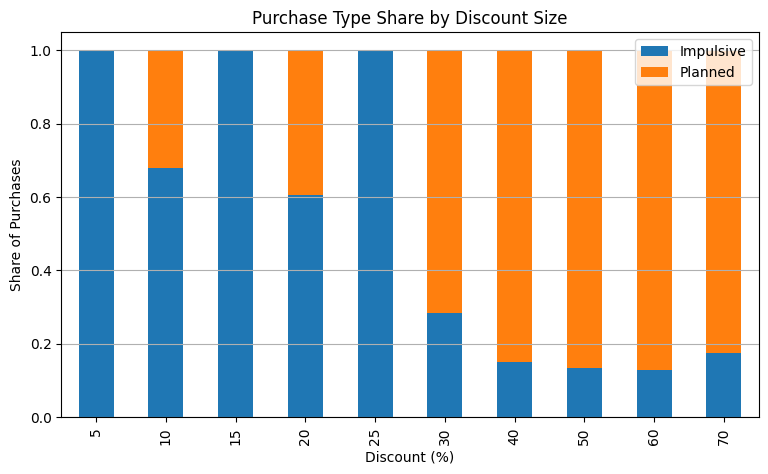

In [90]:
# =====================================================
# Discount → Purchase Type (Stacked Bar)
# =====================================================

discount_stacked = (
    df.groupby(["discount_percent", "impulsive_flag"])
      .size()
      .unstack(fill_value=0)
)

# нормализуем по строкам (внутри каждой скидки = 100%)
discount_stacked = discount_stacked.div(discount_stacked.sum(axis=1), axis=0)

plt.figure(figsize=(9,5))
discount_stacked[[1, 0]].plot(
    kind="bar",
    stacked=True,
    figsize=(9,5)
)

plt.xlabel("Discount (%)")
plt.ylabel("Share of Purchases")
plt.title("Purchase Type Share by Discount Size")
plt.legend(["Impulsive", "Planned"])
plt.grid(axis="y")
plt.show()
